# Explainable Machine Learning for Predicting Ciprofloxacin Resistance in *Escherichia coli*

MSc project notebook. Dataset: Pataki et al. (2020), [AMR_ciprofloxacin](https://github.com/patbaa/AMR_ciprofloxacin)
— 704 *E. coli* isolates with ciprofloxacin MIC measurements.

| Part | Content | Runs where |
|---|---|---|
| 1 | Data inspection and exploration | This notebook |
| — | Genomic feature extraction from the raw sequencing reads | **`aws/extract_features.py` on a Linux server, e.g. AWS EC2** (needs Linux bioinformatics tools; see `aws/README.md`) |
| 2 | Modelling and validation (baselines, Logistic Regression, Random Forest, XGBoost; random vs clade-aware CV) | This notebook |
| 3 | SHAP explainability | This notebook |

**Before running Parts 2 and 3**, run `aws/extract_features.py` and copy `features.csv`,
`qc.csv` and `mash_distances.csv` into the `Data/` folder. Shared helper code is in `src/amr_utils.py`.

*Academic research prototype — not a clinically validated diagnostic tool.*

# Part 1 — Data Inspection and Exploration

In [1]:
%pip install pandas "numpy<2" matplotlib seaborn scikit-learn "xgboost==2.1.4" "shap==0.49.1"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 10)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load the two downloaded files
metadata = pd.read_csv("Data/supplementary_meta_table.csv")
sequencing_metadata = pd.read_csv("Data/meta.tsv", sep="\t")

# Confirm dataset dimensions
print("Supplementary metadata:", metadata.shape)
print("Sequencing metadata:", sequencing_metadata.shape)

# Inspect the target measurement
print("\nMeasurement summary:")
print(metadata["measurement"].describe())

# Inspect the original train/test allocation
print("\nTrain/test allocation:")
print(metadata["train_test"].value_counts())

# Check missing values
print("\nMissing values in supplementary metadata:")
print(metadata.isnull().sum())

Supplementary metadata: (704, 7)
Sequencing metadata: (807, 8)

Measurement summary:
count    704.000000
mean       8.944676
std       16.312792
min        0.010000
25%        0.015000
50%        0.030000
75%        8.000000
max       64.000000
Name: measurement, dtype: float64

Train/test allocation:
train_test
train    438
test     266
Name: count, dtype: int64

Missing values in supplementary metadata:
study_accession         0
sample_accession        0
analysis_accession      0
sample_alias            0
country               266
measurement             0
train_test              0
dtype: int64


In [4]:
# 1. Display all column name
print("Columns in supplementary metadata:")
print(metadata.columns.tolist())

# 2. Display the first five rows
display(metadata.head())

# 3. Inspect the measurement values
print("Unique measurement values:")
print(sorted(metadata["measurement"].unique()))

# 4. Inspect the train/test groups
print("\nSamples per group:")
print(metadata.groupby("train_test")["sample_alias"].count())

# 5. Check for duplicate sample identifiers
print(
    "\nDuplicate sample aliases:",
    metadata["sample_alias"].duplicated().sum()
)

Columns in supplementary metadata:
['study_accession', 'sample_accession', 'analysis_accession', 'sample_alias', 'country', 'measurement', 'train_test']


,study_accession,sample_accession,analysis_accession,sample_alias,country,measurement,train_test
0,PRJEB21131,SAMEA104107449,ERZ448657,M0041-02-16-MC003,United Kingdom,0.015,train
1,PRJEB21131,SAMEA104107450,ERZ448658,M0041-02-16-MC004,United Kingdom,0.015,train
2,PRJEB21131,SAMEA104107451,ERZ448659,M0041-02-16-MC005,United Kingdom,0.015,train
3,PRJEB21131,SAMEA104107452,ERZ448660,M0041-02-16-MC012,United Kingdom,0.015,train
4,PRJEB21131,SAMEA104107453,ERZ448661,M0041-02-16-MC014,United Kingdom,0.015,train


Unique measurement values:
[0.01, 0.012, 0.015, 0.016, 0.023, 0.03, 0.06, 0.12, 0.125, 0.19, 0.25, 0.38, 0.5, 0.75, 1.0, 2.0, 4.0, 8.0, 12.0, 16.0, 24.0, 32.0, 64.0]

Samples per group:
train_test
test     266
train    438
Name: sample_alias, dtype: int64

Duplicate sample aliases: 0


# Part 2 — Modelling and Validation

This part trains and compares models that predict ciprofloxacin resistance from the genomic
features extracted by `aws/extract_features.py`.

| Research question | Addressed in this part by |
|---|---|
| **RQ3** Which model performs best? | Majority-class and rule-based baselines vs Logistic Regression, Random Forest and XGBoost, compared with AUROC, balanced accuracy and MCC |
| **RQ2** Do models generalise to genetically distinct strains? | Random cross-validation vs clade-aware cross-validation (whole lineages held out), plus performance on held-out isolates from lineages never seen in training |
| **RQ1** Which features matter? | Ablation: all features vs known resistance mechanisms only (SHAP analysis follows in Part 3) |

**Preventing data leakage**
- The original train/test split from Pataki et al. is kept. The 266 test isolates are not used for any
  modelling decision and are evaluated once, at the end.
- Rare-feature filtering and hyperparameter tuning happen inside each training fold (nested CV).
- Lineage clusters are computed from genome distances only, never from the resistance labels.

## 2.1 Settings

In [5]:
from pathlib import Path

DATA_DIR = Path("Data")
RESULTS_DIR = Path("results")
MODELS_DIR = Path("models")

# Resistance label. EUCAST clinical breakpoint for ciprofloxacin in Enterobacterales:
# resistant if MIC > 0.5 mg/L. (CLSI alternative: resistant if MIC >= 1 mg/L)
BREAKPOINT = 0.5

# Isolate quality control (from the feature extraction step)
MIN_COVERAGE = 10      # minimum mean read depth over gyrA and parC
MIN_BREADTH = 0.95     # minimum fraction of gyrA and parC covered by >= 5 reads

# Lineage clusters: Mash distance at which the genome-distance tree is cut
# (0.01 is roughly 99% average nucleotide identity)
CLADE_DISTANCE = 0.01
CLADE_DISTANCES_TO_TEST = [0.005, 0.01, 0.02]

N_FOLDS = 5
MIN_FEATURE_COUNT = 3  # features present in fewer isolates are dropped inside each fold
RANDOM_SEED = 42
N_JOBS = -1

TOP_N = 20             # features shown in the SHAP importance plots (Part 3)

In [6]:
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.amr_utils import (CATEGORY_LABELS, METRICS, KnownMechanismRule, MinCountFilter,
                           bootstrap_ci, delong_test, evaluate, feature_category,
                           holm_adjust, known_mechanism_columns, lineage_clusters,
                           mcnemar_test)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

FIG_DIR = RESULTS_DIR / "figures"
for d in [RESULTS_DIR, FIG_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2.2 Load the data
- `supplementary_meta_table.csv`: MIC values and the original train/test split
- `features.csv`, `qc.csv`, `mash_distances.csv`: outputs of `aws/extract_features.py`

In [7]:
needed = ["features.csv", "qc.csv", "mash_distances.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in the {DATA_DIR}/ folder. Run aws/extract_features.py on a Linux "
        "server (see aws/README.md), then copy these files into the Data folder.")

metadata = pd.read_csv(DATA_DIR / "supplementary_meta_table.csv")
features = pd.read_csv(DATA_DIR / "features.csv")
qc = pd.read_csv(DATA_DIR / "qc.csv")
distances = pd.read_csv(DATA_DIR / "mash_distances.csv", index_col=0)

print("Isolates with MIC values:", len(metadata))
print("Isolates with extracted features:", len(features))
print("Genomic features:", features.shape[1] - 1)

# Quality control: remove isolates with low read depth or incomplete coverage of the key
# target genes. Depth is measured directly on gyrA and parC (more reliable than the
# genome-wide estimate, which is 0 for isolates whose read length check failed during extraction).
qc["passed_qc"] = ((qc[["gyrA_depth", "parC_depth"]].min(axis=1) >= MIN_COVERAGE) &
                   (qc["gyrA_breadth"] >= MIN_BREADTH) &
                   (qc["parC_breadth"] >= MIN_BREADTH))
print("Isolates failing QC:", (~qc["passed_qc"]).sum())

data = (metadata[["sample_alias", "country", "measurement", "train_test"]]
        .merge(qc.loc[qc["passed_qc"], ["sample_alias"]], on="sample_alias")
        .merge(features, on="sample_alias")
        .set_index("sample_alias"))
data["resistant"] = (data["measurement"] > BREAKPOINT).astype(int)

# Lineage clustering needs a genome distance for every isolate
no_distance = ~data.index.isin(distances.index)
print("Isolates without a Mash sketch (excluded):", no_distance.sum())
data = data[~no_distance]

feature_cols = [c for c in features.columns if c != "sample_alias"]
print("\nIsolates used for modelling:", len(data))
display(data.groupby("train_test")["resistant"].agg(isolates="count", resistant="sum", proportion_resistant="mean"))

Isolates with MIC values: 704
Isolates with extracted features: 703
Genomic features: 273
Isolates failing QC: 12
Isolates without a Mash sketch (excluded): 0

Isolates used for modelling: 691


,isolates,resistant,proportion_resistant
train_test,,,
test,260,162,0.623
train,431,66,0.153


## 2.3 Resistance labels
Ciprofloxacin MICs are typically bimodal: a susceptible population at low MICs and a resistant
population at high MICs. Few isolates close to the breakpoint means the binary label is robust.

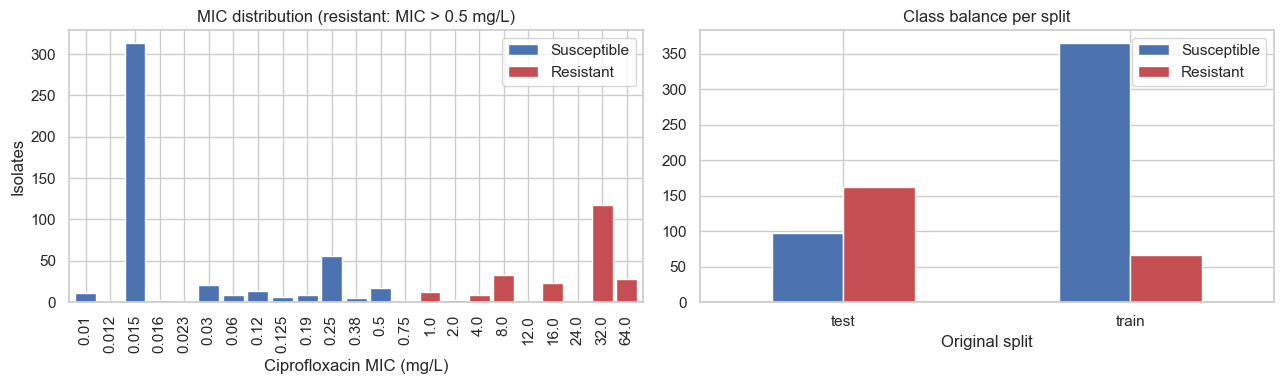

Isolates within one doubling dilution of the breakpoint: 91 (13.2%)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mic_counts = data.groupby(["measurement", "resistant"]).size().unstack(fill_value=0)
mic_counts.plot(kind="bar", stacked=True, ax=axes[0], color=["#4C72B0", "#C44E52"], width=0.85)
axes[0].set_xlabel("Ciprofloxacin MIC (mg/L)")
axes[0].set_ylabel("Isolates")
axes[0].set_title(f"MIC distribution (resistant: MIC > {BREAKPOINT} mg/L)")
axes[0].legend(["Susceptible", "Resistant"])

split_counts = data.groupby(["train_test", "resistant"]).size().unstack(fill_value=0)
split_counts.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#C44E52"], rot=0)
axes[1].set_xlabel("Original split")
axes[1].set_title("Class balance per split")
axes[1].legend(["Susceptible", "Resistant"])
plt.tight_layout()
plt.savefig(FIG_DIR / "mic_distribution.png", dpi=200)
plt.show()

near = data["measurement"].between(BREAKPOINT / 2, BREAKPOINT * 2)
print(f"Isolates within one doubling dilution of the breakpoint: {near.sum()} ({near.mean():.1%})")

## 2.4 Feature overview
Each feature is labelled as a known resistance mechanism (QRDR target-site mutation, acquired gene,
efflux regulator truncation) or as another substitution, most of which are lineage-associated
polymorphisms. This labelling is used in the ablation below and in the SHAP analysis.

In [9]:
feature_info = pd.DataFrame({
    "feature": feature_cols,
    "category": [feature_category(f) for f in feature_cols],
    "isolates_with_feature": data[feature_cols].sum().to_numpy(),
})
feature_info["% in resistant"] = 100 * data.loc[data.resistant == 1, feature_cols].mean().to_numpy()
feature_info["% in susceptible"] = 100 * data.loc[data.resistant == 0, feature_cols].mean().to_numpy()
feature_info.to_csv(RESULTS_DIR / "feature_overview.csv", index=False)

print("Features per category:")
display(feature_info["category"].map(CATEGORY_LABELS).value_counts().to_frame("features"))
print("Most common known resistance mechanisms:")
display(feature_info[feature_info.category != "other"]
        .sort_values("isolates_with_feature", ascending=False).head(15).round(1))

Features per category:


,features
category,
Other substitution (possible lineage marker),231
Target-site QRDR mutation,30
Acquired resistance gene,6
Efflux regulator truncation,6


Most common known resistance mechanisms:


,feature,category,isolates_with_feature,% in resistant,% in susceptible
77,gyrA_S83L,target_qrdr,299,97.4,16.6
194,parC_S80I,target_qrdr,210,92.1,0.0
55,gyrA_D87N,target_qrdr,208,90.8,0.2
162,parC_E84V,target_qrdr,116,50.9,0.0
238,parE_S458A,target_qrdr,38,16.7,0.0
...,...,...,...,...,...
217,parE_D463N,target_qrdr,5,2.2,0.0
195,parC_S80R,target_qrdr,5,1.8,0.2
153,parC_A90V,target_qrdr,5,2.2,0.0
4,acq_qnrB,acquired,4,0.4,0.6


## 2.5 Lineage clusters
Isolates are grouped into lineages by hierarchical clustering of their Mash genome distances.
Clade-aware cross-validation keeps every isolate of a lineage in the same fold, so the model is always
tested on lineages it has not seen. If resistance is concentrated in a few lineages, a model can score
well in random CV by recognising the lineage instead of the resistance mechanism.

Lineage clusters at Mash distance 0.01: 294


Singleton clusters: 203
Largest cluster: 105 isolates (15.2%)


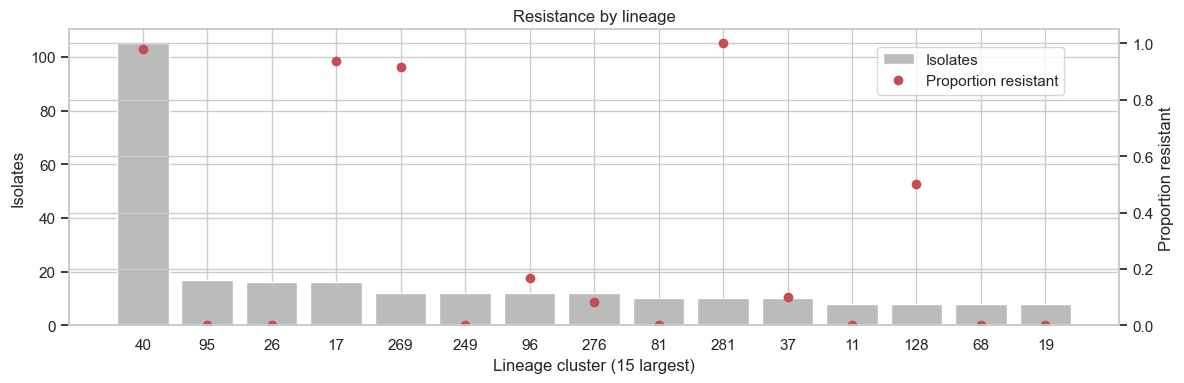

In [10]:
distances = distances.loc[data.index, data.index]
data["clade"] = lineage_clusters(distances, CLADE_DISTANCE)

clade_summary = (data.groupby("clade")
                 .agg(isolates=("resistant", "size"), proportion_resistant=("resistant", "mean"))
                 .sort_values("isolates", ascending=False))
print(f"Lineage clusters at Mash distance {CLADE_DISTANCE}: {len(clade_summary)}")
print(f"Singleton clusters: {(clade_summary.isolates == 1).sum()}")
print(f"Largest cluster: {clade_summary.isolates.max()} isolates "
      f"({clade_summary.isolates.max() / len(data):.1%})")

top = clade_summary.head(15)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(top.index.astype(str), top["isolates"], color="#BBBBBB", label="Isolates")
ax2 = ax.twinx()
ax2.plot(top.index.astype(str), top["proportion_resistant"], "o", color="#C44E52", label="Proportion resistant")
ax2.set_ylim(0, 1.05)
ax.set_xlabel("Lineage cluster (15 largest)")
ax.set_ylabel("Isolates")
ax2.set_ylabel("Proportion resistant")
ax.set_title("Resistance by lineage")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig(FIG_DIR / "resistance_by_lineage.png", dpi=200)
plt.show()

## 2.6 Models
| Model | Role |
|---|---|
| Majority class | Lower bound: always predicts the most common class |
| Known-mechanism rule | Literature baseline: resistant if an isolate carries at least *k* known mechanisms (k chosen on the training data) |
| Logistic Regression | Interpretable linear model (L1 or L2 regularisation) |
| Random Forest | Ensemble of decision trees, captures interactions between mutations |
| XGBoost | Gradient-boosted trees |

Each ML model is a pipeline (rare-feature filter → model) tuned with an inner 3-fold grid search on
AUROC, so tuning only ever sees the training fold. Class weights compensate for class imbalance.

In [11]:
def tuned(model, grid):
    pipeline = Pipeline([("filter", MinCountFilter(MIN_FEATURE_COUNT)), ("model", model)])
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
    return GridSearchCV(pipeline, {f"model__{k}": v for k, v in grid.items()},
                        cv=inner_cv, scoring="roc_auc", n_jobs=N_JOBS)

def make_models():
    return {
        "Majority class": DummyClassifier(strategy="most_frequent"),
        "Known-mechanism rule": KnownMechanismRule(),
        "Logistic Regression": tuned(
            LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=5000),
            {"C": [0.01, 0.1, 1, 10], "penalty": ["l1", "l2"]}),
        "Random Forest": tuned(
            RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   random_state=RANDOM_SEED, n_jobs=1),
            {"max_depth": [None, 6], "min_samples_leaf": [1, 3], "max_features": ["sqrt", 0.3]}),
        "XGBoost": tuned(
            XGBClassifier(n_estimators=300, eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=1),
            {"max_depth": [2, 4], "learning_rate": [0.05, 0.1], "subsample": [0.8, 1.0]}),
    }

ML_MODELS = ["Logistic Regression", "Random Forest", "XGBoost"]
MODEL_ORDER = list(make_models())

## 2.7 Random vs clade-aware cross-validation
Both schemes use 5 folds on the development set (original training isolates) with stratification by
class. In clade-aware CV, all isolates from one lineage cluster are placed in the same fold.

In [12]:
dev = data[data.train_test == "train"]
test = data[data.train_test == "test"]
X_dev, y_dev, groups_dev = dev[feature_cols], dev["resistant"], dev["clade"]
X_test, y_test = test[feature_cols], test["resistant"]
print(f"Development set: {len(dev)} isolates ({y_dev.mean():.1%} resistant), {groups_dev.nunique()} lineages")
print(f"Held-out test set: {len(test)} isolates ({y_test.mean():.1%} resistant)")

SPLITTERS = {
    "Random CV": StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED),
    "Clade-aware CV": StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED),
}

def cross_validate(models, X, y, groups, scheme):
    rows = []
    for name, estimator in models.items():
        start = time.time()
        for fold, (train_idx, test_idx) in enumerate(SPLITTERS[scheme].split(X, y, groups)):
            model = clone(estimator).fit(X.iloc[train_idx], y.iloc[train_idx])
            prob = model.predict_proba(X.iloc[test_idx])[:, 1]
            rows.append({"scheme": scheme, "model": name, "fold": fold,
                         "test_isolates": len(test_idx), **evaluate(y.iloc[test_idx], prob)})
        print(f"  {scheme:15s} {name:22s} {time.time() - start:6.1f}s")
    return rows

cv_rows = []
for scheme in SPLITTERS:
    cv_rows += cross_validate(make_models(), X_dev, y_dev, groups_dev, scheme)
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(RESULTS_DIR / "cv_fold_results.csv", index=False)

Development set: 431 isolates (15.3% resistant), 218 lineages
Held-out test set: 260 isolates (62.3% resistant)


  Random CV       Majority class            0.3s


  Random CV       Known-mechanism rule      0.3s


  Random CV       Logistic Regression       8.2s


  Random CV       Random Forest            43.6s


  Random CV       XGBoost                  10.9s


  Clade-aware CV  Majority class            0.4s


  Clade-aware CV  Known-mechanism rule      0.6s


  Clade-aware CV  Logistic Regression       1.7s


  Clade-aware CV  Random Forest            36.3s


  Clade-aware CV  XGBoost                  10.7s


In [13]:
def summarise(results, by):
    summary = results.groupby(by)[METRICS].agg(["mean", "std"])
    formatted = pd.DataFrame(index=summary.index)
    for m in METRICS:
        formatted[m] = (summary[(m, "mean")].map("{:.3f}".format) + " ± " +
                        summary[(m, "std")].map("{:.3f}".format))
    return formatted

cv_summary = summarise(cv_results, ["scheme", "model"])
cv_summary = cv_summary.reindex(pd.MultiIndex.from_product([SPLITTERS, MODEL_ORDER]))
cv_summary.to_csv(RESULTS_DIR / "cv_summary.csv")
print("Mean ± standard deviation across the 5 folds")
display(cv_summary)

Mean ± standard deviation across the 5 folds


AUROC balanced_accuracy  \
Random CV      Majority class        0.500 ± 0.000     0.500 ± 0.000   
               Known-mechanism rule  0.984 ± 0.018     0.948 ± 0.042   
               Logistic Regression   0.989 ± 0.015     0.938 ± 0.039   
               Random Forest         0.985 ± 0.020     0.930 ± 0.035   
               XGBoost               0.988 ± 0.020     0.938 ± 0.034   
Clade-aware CV Majority class        0.500 ± 0.000     0.500 ± 0.000   
               Known-mechanism rule  0.981 ± 0.027     0.935 ± 0.047   
               Logistic Regression   0.983 ± 0.028     0.917 ± 0.047   
               Random Forest         0.983 ± 0.028     0.911 ± 0.075   
               XGBoost               0.984 ± 0.029     0.942 ± 0.058   

                                               MCC    sensitivity  \
Random CV      Majority class        0.000 ± 0.000  0.000 ± 0.000   
               Known-mechanism rule  0.910 ± 0.063  0.908 ± 0.084   
               Logistic Regression   0.879 ± 0.059  0.895 ± 0.086   
               Random Forest         0.870 ± 0.030  0.879 ± 0.087   
               XGBoost               0.918 ± 0.040  0.878 ± 0.070   
Clade-aware CV Majority class        0.000 ± 0.000  0.000 ± 0.000   
               Known-mechanism rule  0.886 ± 0.085  0.881 ± 0.092   
               Logistic Regression   0.848 ± 0.048  0.856 ± 0.116   
               Random Forest         0.861 ± 0.126  0.827 ± 0.142   
               XGBoost               0.912 ± 0.062  0.887 ± 0.119   

                                       specificity  
Random CV      Majority class        1.000 ± 0.000  
               Known-mechanism rule  0.989 ± 0.015  
               Logistic Regression   0.981 ± 0.021  
               Random Forest         0.981 ± 0.021  
               XGBoost               0.997 ± 0.006  
Clade-aware CV Majority class        1.000 ± 0.000  
               Known-mechanism rule  0.989 ± 0.011  
               Logistic Regression   0.978 ± 0.026  
               Random Forest         0.994 ± 0.009  
               XGBoost               0.997 ± 0.006

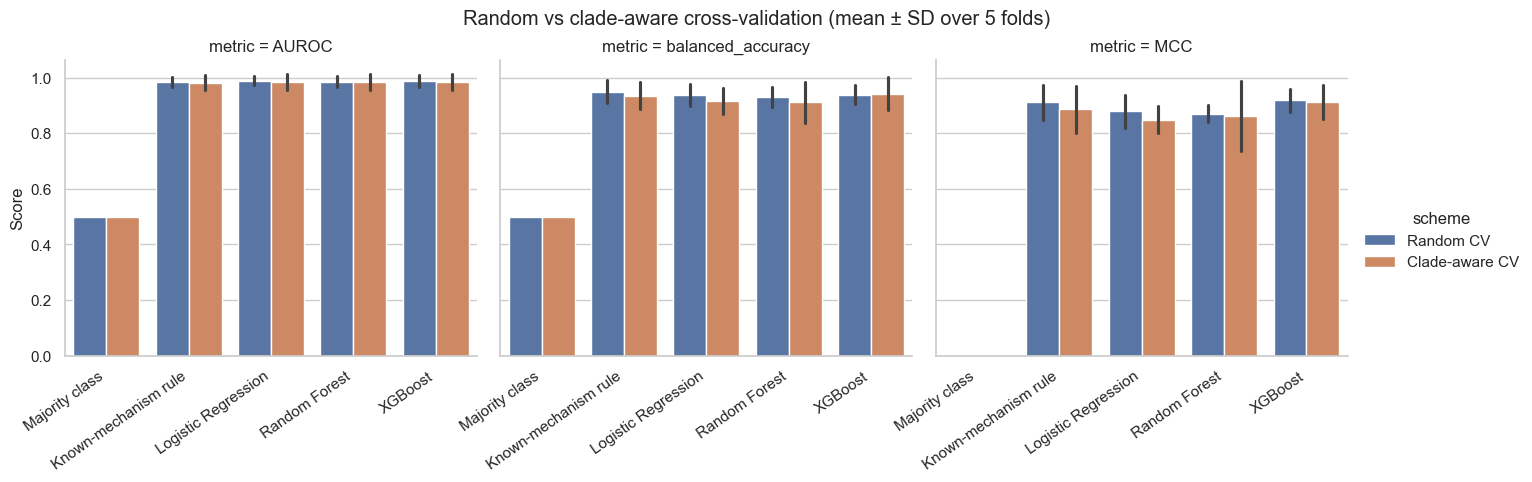

Generalisation gap (random CV minus clade-aware CV; positive = worse on unseen lineages)


,AUROC,balanced_accuracy,MCC
model,,,
Majority class,0.000,0.000,0.000
Known-mechanism rule,0.003,0.014,0.024
Logistic Regression,0.006,0.021,0.031
Random Forest,0.002,0.019,0.009
XGBoost,0.004,-0.005,0.005


In [14]:
plot_data = cv_results.melt(id_vars=["scheme", "model"], value_vars=["AUROC", "balanced_accuracy", "MCC"],
                            var_name="metric", value_name="score")
g = sns.catplot(data=plot_data, x="model", y="score", hue="scheme", col="metric", kind="bar",
                order=MODEL_ORDER, errorbar="sd", height=4, aspect=1.15,
                palette=["#4C72B0", "#DD8452"])
g.set_xticklabels(rotation=35, ha="right")
g.set_axis_labels("", "Score")
g.figure.suptitle("Random vs clade-aware cross-validation (mean ± SD over 5 folds)", y=1.03)
plt.savefig(FIG_DIR / "cv_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

means = cv_results.groupby(["model", "scheme"])[["AUROC", "balanced_accuracy", "MCC"]].mean().unstack()
gap = pd.DataFrame({m: means[(m, "Random CV")] - means[(m, "Clade-aware CV")]
                    for m in ["AUROC", "balanced_accuracy", "MCC"]}).loc[MODEL_ORDER]
gap.to_csv(RESULTS_DIR / "generalisation_gap.csv")
print("Generalisation gap (random CV minus clade-aware CV; positive = worse on unseen lineages)")
display(gap.round(3))

## 2.8 Ablation: known resistance mechanisms only
If the models mainly rely on established mechanisms, removing all other substitutions (likely lineage
markers) should barely change clade-aware performance. A large drop would show that lineage markers
carry predictive information beyond the known mechanisms.

In [15]:
known_cols = known_mechanism_columns(feature_cols)
print(f"Known-mechanism features: {len(known_cols)} of {len(feature_cols)}")

ml_models = {k: v for k, v in make_models().items() if k in ML_MODELS}
ablation_rows = []
for scheme in SPLITTERS:
    ablation_rows += [dict(r, features="Known mechanisms only")
                      for r in cross_validate(ml_models, X_dev[known_cols], y_dev, groups_dev, scheme)]
ablation = pd.concat([
    cv_results[cv_results.model.isin(ML_MODELS)].assign(features="All features"),
    pd.DataFrame(ablation_rows),
])
ablation.to_csv(RESULTS_DIR / "ablation_fold_results.csv", index=False)
ablation_summary = summarise(ablation, ["scheme", "model", "features"])[["AUROC", "balanced_accuracy", "MCC"]]
ablation_summary.to_csv(RESULTS_DIR / "ablation_summary.csv")
display(ablation_summary)

Known-mechanism features: 42 of 273


  Random CV       Logistic Regression       1.0s


  Random CV       Random Forest            34.7s


  Random CV       XGBoost                   5.0s


  Clade-aware CV  Logistic Regression       1.3s


  Clade-aware CV  Random Forest            33.8s


  Clade-aware CV  XGBoost                   5.6s


AUROC  \
scheme         model               features                               
Clade-aware CV Logistic Regression All features           0.983 ± 0.028   
                                   Known mechanisms only  0.985 ± 0.027   
               Random Forest       All features           0.983 ± 0.028   
                                   Known mechanisms only  0.977 ± 0.043   
               XGBoost             All features           0.984 ± 0.029   
...                                                                 ...   
Random CV      Logistic Regression Known mechanisms only  0.987 ± 0.019   
               Random Forest       All features           0.985 ± 0.020   
                                   Known mechanisms only  0.988 ± 0.019   
               XGBoost             All features           0.988 ± 0.020   
                                   Known mechanisms only  0.987 ± 0.019   

                                                         balanced_accuracy  \
scheme         model               features                                  
Clade-aware CV Logistic Regression All features              0.917 ± 0.047   
                                   Known mechanisms only     0.960 ± 0.038   
               Random Forest       All features              0.911 ± 0.075   
                                   Known mechanisms only     0.920 ± 0.049   
               XGBoost             All features              0.942 ± 0.058   
...                                                                    ...   
Random CV      Logistic Regression Known mechanisms only     0.964 ± 0.019   
               Random Forest       All features              0.930 ± 0.035   
                                   Known mechanisms only     0.929 ± 0.033   
               XGBoost             All features              0.938 ± 0.034   
                                   Known mechanisms only     0.939 ± 0.035   

                                                                    MCC  
scheme         model               features                              
Clade-aware CV Logistic Regression All features           0.848 ± 0.048  
                                   Known mechanisms only  0.880 ± 0.047  
               Random Forest       All features           0.861 ± 0.126  
                                   Known mechanisms only  0.887 ± 0.060  
               XGBoost             All features           0.912 ± 0.062  
...                                                                 ...  
Random CV      Logistic Regression Known mechanisms only  0.893 ± 0.046  
               Random Forest       All features           0.870 ± 0.030  
                                   Known mechanisms only  0.901 ± 0.056  
               XGBoost             All features           0.918 ± 0.040  
                                   Known mechanisms only  0.927 ± 0.043  

[12 rows x 3 columns]

## 2.9 Sensitivity to the lineage definition
The clade-aware result depends on how coarsely lineages are defined. XGBoost is re-evaluated with
lineage clusters cut at several genome-distance thresholds (larger distance = fewer, broader lineages
= a stricter test).

In [16]:
sensitivity_rows = []
for threshold in CLADE_DISTANCES_TO_TEST:
    groups = lineage_clusters(distances, threshold).loc[dev.index]
    rows = cross_validate({"XGBoost": make_models()["XGBoost"]}, X_dev, y_dev, groups, "Clade-aware CV")
    for r in rows:
        r.update(clade_distance=threshold, lineages=groups.nunique())
    sensitivity_rows += rows
sensitivity = (pd.DataFrame(sensitivity_rows)
               .groupby(["clade_distance", "lineages"])[["AUROC", "balanced_accuracy", "MCC"]].agg(["mean", "std"]))
sensitivity.to_csv(RESULTS_DIR / "clade_threshold_sensitivity.csv")
display(sensitivity.round(3))

  Clade-aware CV  XGBoost                  11.6s


  Clade-aware CV  XGBoost                  10.8s


  Clade-aware CV  XGBoost                  12.3s


AUROC        balanced_accuracy           MCC       
                          mean    std              mean    std   mean    std
clade_distance lineages                                                     
0.005          377       0.994  0.008             0.914  0.153  0.885  0.206
0.010          218       0.984  0.029             0.942  0.058  0.912  0.062
0.020          43        0.993  0.009             0.938  0.057  0.671  0.388

## 2.10 Final models and held-out test set
Each model is tuned and trained on the full development set, then evaluated once on the 266 held-out
isolates. 95% confidence intervals come from 1,000 bootstrap resamples of the test set.

The test isolates come from different studies than the development isolates, so this is also a test of
transfer to a new population. Results are additionally split by whether an isolate's lineage was present
in the development set.

In [17]:
final_models, test_probs = {}, {}
for name, estimator in make_models().items():
    model = clone(estimator).fit(X_dev, y_dev)
    final_models[name] = model.best_estimator_ if isinstance(model, GridSearchCV) else model
    test_probs[name] = final_models[name].predict_proba(X_test)[:, 1]
    if isinstance(model, GridSearchCV):
        params = {k.replace("model__", ""): v for k, v in model.best_params_.items()}
        print(f"{name}: best parameters {params}")
    joblib.dump(final_models[name], MODELS_DIR / f"{name.lower().replace(' ', '_').replace('-', '_')}.joblib")

print(f"Known-mechanism rule threshold: >= {final_models['Known-mechanism rule'].threshold_} mechanisms")

holdout = pd.concat({name: bootstrap_ci(y_test, prob, seed=RANDOM_SEED)
                     for name, prob in test_probs.items()}, names=["model", "metric"])
holdout.to_csv(RESULTS_DIR / "holdout_results.csv")
holdout_table = holdout.apply(lambda r: f"{r.estimate:.3f} ({r.ci_low:.3f}–{r.ci_high:.3f})", axis=1).unstack()
display(holdout_table[METRICS].loc[MODEL_ORDER])

Logistic Regression: best parameters {'C': 10, 'penalty': 'l2'}


Random Forest: best parameters {'max_depth': 6, 'max_features': 0.3, 'min_samples_leaf': 1}


XGBoost: best parameters {'learning_rate': 0.05, 'max_depth': 2, 'subsample': 1.0}
Known-mechanism rule threshold: >= 2 mechanisms


metric,AUROC,balanced_accuracy,MCC,sensitivity,specificity
model,,,,,
Majority class,0.500 (0.500–0.500),0.500 (0.500–0.500),0.000 (0.000–0.000),0.000 (0.000–0.000),1.000 (1.000–1.000)
Known-mechanism rule,0.999 (0.998–1.000),0.980 (0.957–0.995),0.968 (0.931–0.992),1.000 (1.000–1.000),0.959 (0.913–0.991)
Logistic Regression,0.998 (0.993–1.000),0.988 (0.972–0.997),0.968 (0.930–0.992),0.975 (0.945–0.994),1.000 (1.000–1.000)
Random Forest,0.998 (0.995–1.000),0.983 (0.964–0.997),0.960 (0.919–0.992),0.975 (0.945–0.994),0.990 (0.967–1.000)
XGBoost,0.997 (0.992–1.000),0.988 (0.972–0.997),0.968 (0.930–0.992),0.975 (0.945–0.994),1.000 (1.000–1.000)


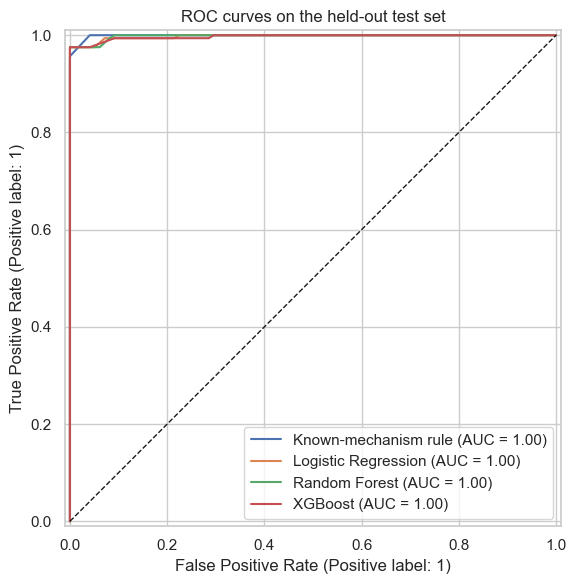

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in MODEL_ORDER[1:]:
    RocCurveDisplay.from_predictions(y_test, test_probs[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("ROC curves on the held-out test set")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_holdout.png", dpi=200)
plt.show()

In [19]:
seen_lineages = set(dev["clade"])
test_seen = test["clade"].isin(seen_lineages)
print(f"Test isolates from lineages seen in development: {test_seen.sum()}; unseen: {(~test_seen).sum()}")

rows = []
for name in MODEL_ORDER:
    for label, mask in [("Seen lineage", test_seen), ("Unseen lineage", ~test_seen)]:
        if mask.sum() >= 10:
            rows.append({"model": name, "subset": label, "isolates": int(mask.sum()),
                         **evaluate(y_test[mask], test_probs[name][mask.to_numpy()])})
lineage_holdout = pd.DataFrame(rows).set_index(["model", "subset"])
lineage_holdout.to_csv(RESULTS_DIR / "holdout_by_lineage.csv")
display(lineage_holdout.round(3))

Test isolates from lineages seen in development: 142; unseen: 118


isolates  AUROC  balanced_accuracy  \
model                subset                                               
Majority class       Seen lineage         142  0.500              0.500   
                     Unseen lineage       118  0.500              0.500   
Known-mechanism rule Seen lineage         142  0.999              0.950   
                     Unseen lineage       118  0.999              0.987   
Logistic Regression  Seen lineage         142  0.997              0.992   
                     Unseen lineage       118  0.995              0.975   
Random Forest        Seen lineage         142  0.997              0.967   
                     Unseen lineage       118  0.997              0.975   
XGBoost              Seen lineage         142  0.997              0.992   
                     Unseen lineage       118  0.993              0.975   

                                       MCC  sensitivity  specificity  
model                subset                                           
Majority class       Seen lineage    0.000        0.000        1.000  
                     Unseen lineage  0.000        0.000        1.000  
Known-mechanism rule Seen lineage    0.941        1.000        0.900  
                     Unseen lineage  0.963        1.000        0.974  
Logistic Regression  Seen lineage    0.946        0.984        1.000  
                     Unseen lineage  0.962        0.950        1.000  
Random Forest        Seen lineage    0.915        0.984        0.950  
                     Unseen lineage  0.962        0.950        1.000  
XGBoost              Seen lineage    0.946        0.984        1.000  
                     Unseen lineage  0.962        0.950        1.000

## 2.11 Statistical comparison of models (RQ3)
The confidence intervals above overlap, so this section tests formally whether any model is
better than another on the held-out test set. Every pair of models (excluding the majority-class
baseline) is compared with two tests:

- **DeLong test**: is the difference in AUROC larger than expected by chance? It accounts for
  both models being scored on the same isolates.
- **Exact McNemar test**: at the 0.5 threshold, does one model misclassify significantly more
  isolates than the other? Only isolates where the two models disagree are informative.

With six pairwise comparisons, p-values are Holm-Bonferroni adjusted to keep the overall chance
of a false positive at 5%.

In [20]:
from itertools import combinations

compared = [m for m in MODEL_ORDER if m != "Majority class"]
rows = []
for a, b in combinations(compared, 2):
    auc_a, auc_b, z, p_auc = delong_test(y_test, test_probs[a], test_probs[b])
    a_only, b_only, p_errors = mcnemar_test(y_test, test_probs[a] >= 0.5, test_probs[b] >= 0.5)
    rows.append({"model_A": a, "model_B": b,
                 "AUROC_A": auc_a, "AUROC_B": auc_b, "DeLong_z": z, "DeLong_p": p_auc,
                 "A_right_B_wrong": a_only, "A_wrong_B_right": b_only, "McNemar_p": p_errors})

comparison = pd.DataFrame(rows)
comparison["DeLong_p_Holm"] = holm_adjust(comparison["DeLong_p"])
comparison["McNemar_p_Holm"] = holm_adjust(comparison["McNemar_p"])
comparison["significant (p < 0.05)"] = ((comparison["DeLong_p_Holm"] < 0.05) |
                                        (comparison["McNemar_p_Holm"] < 0.05)).map({True: "yes", False: "no"})
comparison.to_csv(RESULTS_DIR / "model_comparison_tests.csv", index=False)

errors = pd.Series({m: int(((test_probs[m] >= 0.5) != y_test.to_numpy()).sum()) for m in compared},
                   name="misclassified test isolates")
print(f"Misclassified isolates out of {len(y_test)}:")
display(errors.to_frame())
display(comparison.round({"AUROC_A": 4, "AUROC_B": 4, "DeLong_z": 2, "DeLong_p": 3, "McNemar_p": 3,
                          "DeLong_p_Holm": 3, "McNemar_p_Holm": 3}))

n_significant = (comparison["significant (p < 0.05)"] == "yes").sum()
print(f"Pairs with a significant difference after Holm correction: {n_significant} of {len(comparison)}")

Misclassified isolates out of 260:


,misclassified test isolates
Known-mechanism rule,4
Logistic Regression,4
Random Forest,5
XGBoost,4


,model_A,model_B,AUROC_A,AUROC_B,DeLong_z,DeLong_p,A_right_B_wrong,A_wrong_B_right,McNemar_p,DeLong_p_Holm,McNemar_p_Holm,significant (p < 0.05)
0,Known-mechanism rule,Logistic Regression,0.999,0.998,1.08,0.279,4,4,1.0,1.0,1.0,no
1,Known-mechanism rule,Random Forest,0.999,0.998,0.98,0.327,5,4,1.0,1.0,1.0,no
2,Known-mechanism rule,XGBoost,0.999,0.997,1.15,0.251,4,4,1.0,1.0,1.0,no
3,Logistic Regression,Random Forest,0.998,0.998,-0.72,0.472,1,0,1.0,1.0,1.0,no
4,Logistic Regression,XGBoost,0.998,0.997,0.76,0.450,0,0,1.0,1.0,1.0,no
5,Random Forest,XGBoost,0.998,0.997,0.86,0.392,0,1,1.0,1.0,1.0,no


Pairs with a significant difference after Holm correction: 0 of 6


## 2.12 Save the final models and data
Saved for reuse (e.g. by a Streamlit demonstration app) without re-running the analysis.

In [21]:
joblib.dump({
    "X_dev": X_dev, "y_dev": y_dev, "X_test": X_test, "y_test": y_test,
    "clades": data["clade"], "metadata": data[["country", "measurement", "train_test"]],
    "feature_cols": feature_cols, "breakpoint": BREAKPOINT, "clade_distance": CLADE_DISTANCE,
}, MODELS_DIR / "datasets.joblib")
print("Saved models:", sorted(p.name for p in MODELS_DIR.glob("*.joblib")))
print("Saved results:", sorted(p.name for p in RESULTS_DIR.glob("*.csv")))

Saved models: ['datasets.joblib', 'known_mechanism_rule.joblib', 'logistic_regression.joblib', 'majority_class.joblib', 'random_forest.joblib', 'xgboost.joblib']
Saved results: ['ablation_fold_results.csv', 'ablation_summary.csv', 'clade_threshold_sensitivity.csv', 'cv_fold_results.csv', 'cv_summary.csv', 'feature_overview.csv', 'generalisation_gap.csv', 'holdout_by_lineage.csv', 'holdout_results.csv', 'model_comparison_tests.csv', 'shap_importance_logistic_regression.csv', 'shap_importance_random_forest.csv', 'shap_importance_xgboost.csv', 'shap_lineage_markers.csv', 'shap_share_by_category.csv']


# Part 3 — SHAP Explainability

This part explains the final models from Part 2 with SHAP (SHapley Additive exPlanations).

- **RQ1:** Which genetic features drive the predictions, and are they the established resistance
  mechanisms (gyrA S83/D87, parC S80/E84, qnr genes)?
- **RQ2:** Do the models also rely on substitutions that are not resistance mechanisms but mark
  particular lineages?

SHAP values are computed on the held-out test isolates. A SHAP value shows how much a feature pushed
one isolate's prediction towards resistant (positive) or susceptible (negative). SHAP describes the
model's behaviour; it is not evidence of biological causation.

## 3.1 Models to explain

In [22]:
# The three tuned ML models from Part 2 (the baselines have nothing to explain)
models = {name: final_models[name] for name in ML_MODELS}
clades = data["clade"]
print(f"Explaining {list(models)} on {len(X_test)} test isolates ({y_test.mean():.1%} resistant)")
print("shap", shap.__version__)

Explaining ['Logistic Regression', 'Random Forest', 'XGBoost'] on 260 test isolates (62.3% resistant)
shap 0.49.1


## 3.2 Compute SHAP values
Each model is a pipeline (rare-feature filter → model). SHAP is applied to the model step using the
features that passed the filter. Tree models use the exact TreeExplainer; Logistic Regression uses the
LinearExplainer with the development set as background. All values are on the log-odds scale.

In [23]:
explanations = {}
for name, pipeline in models.items():
    X_dev_t = pipeline[:-1].transform(X_dev)
    X_test_t = pipeline[:-1].transform(X_test)
    estimator = pipeline[-1]
    if name == "Logistic Regression":
        explainer = shap.LinearExplainer(estimator, X_dev_t)
    else:
        explainer = shap.TreeExplainer(estimator)
    explanation = explainer(X_test_t)
    if explanation.values.ndim == 3:  # Random Forest returns one set per class
        explanation = explanation[:, :, 1]
    explanations[name] = explanation
    print(f"{name}: {X_test_t.shape[1]} features after filtering")

Logistic Regression: 69 features after filtering


Random Forest: 69 features after filtering
XGBoost: 69 features after filtering


## 3.3 Global feature importance
Mean |SHAP| is the average size of a feature's contribution across the test isolates. Bars are
coloured by feature category.

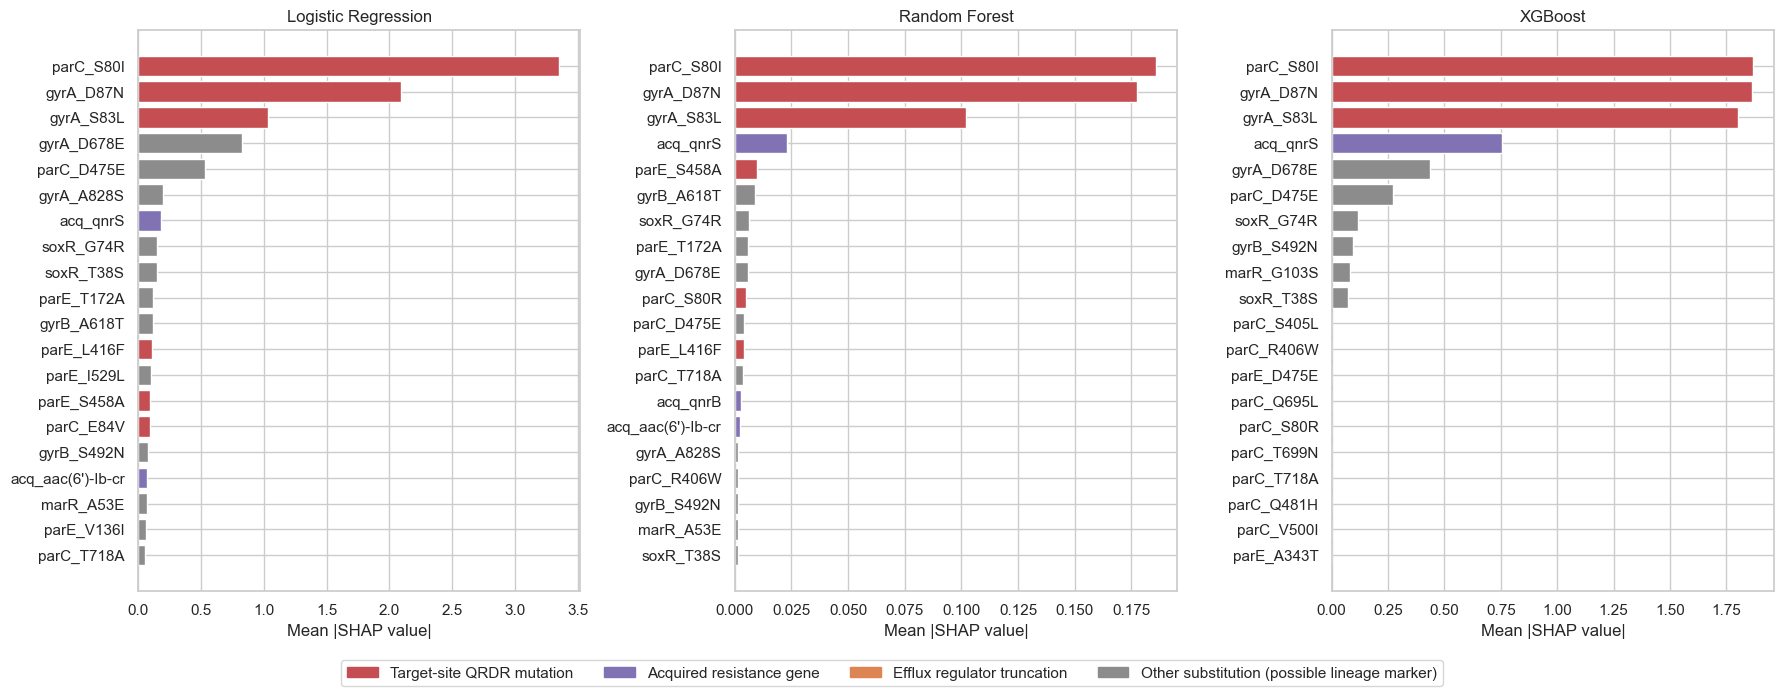

In [24]:
CATEGORY_COLOURS = {"target_qrdr": "#C44E52", "acquired": "#8172B3",
                    "efflux_truncation": "#DD8452", "other": "#8C8C8C"}

importance_tables = {}
for name, explanation in explanations.items():
    table = pd.DataFrame({
        "feature": explanation.feature_names,
        "mean_abs_shap": np.abs(explanation.values).mean(axis=0),
        "mean_shap_when_present": [
            explanation.values[explanation.data[:, i] == 1, i].mean() if (explanation.data[:, i] == 1).any() else np.nan
            for i in range(len(explanation.feature_names))],
    })
    table["category"] = table["feature"].map(feature_category)
    table = table.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    table["rank"] = table.index + 1
    importance_tables[name] = table
    table.to_csv(RESULTS_DIR / f"shap_importance_{name.lower().replace(' ', '_')}.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (name, table) in zip(axes, importance_tables.items()):
    top = table.head(TOP_N).iloc[::-1]
    ax.barh(top["feature"], top["mean_abs_shap"], color=top["category"].map(CATEGORY_COLOURS))
    ax.set_title(name)
    ax.set_xlabel("Mean |SHAP value|")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLOURS.values()]
fig.legend(handles, [CATEGORY_LABELS[k] for k in CATEGORY_COLOURS], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(FIG_DIR / "shap_importance_all_models.png", dpi=200)
plt.show()

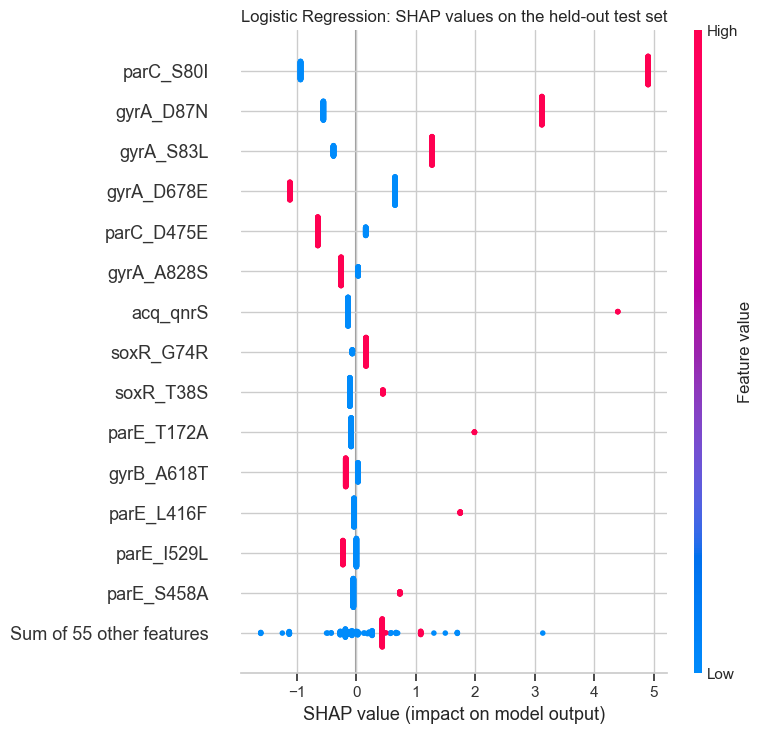

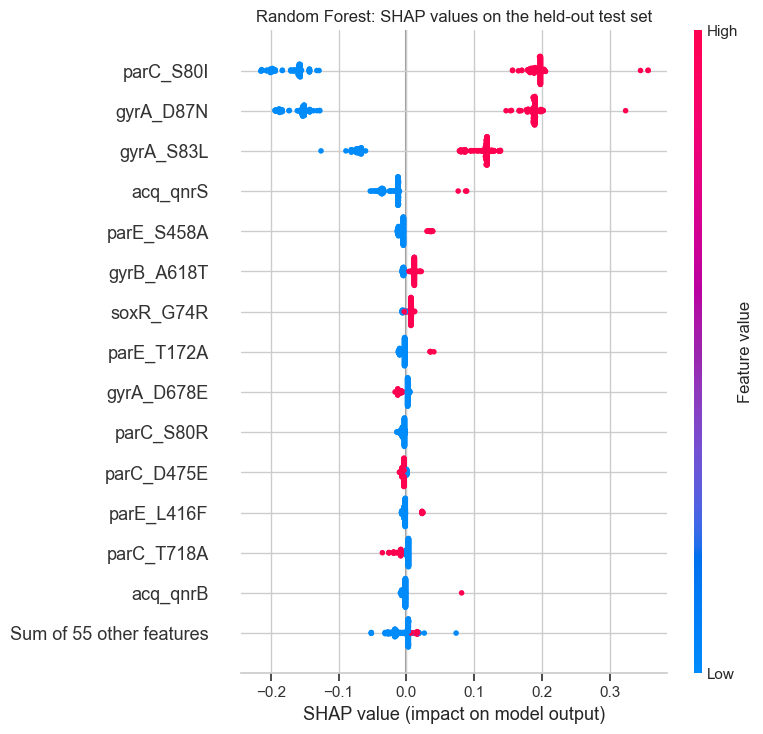

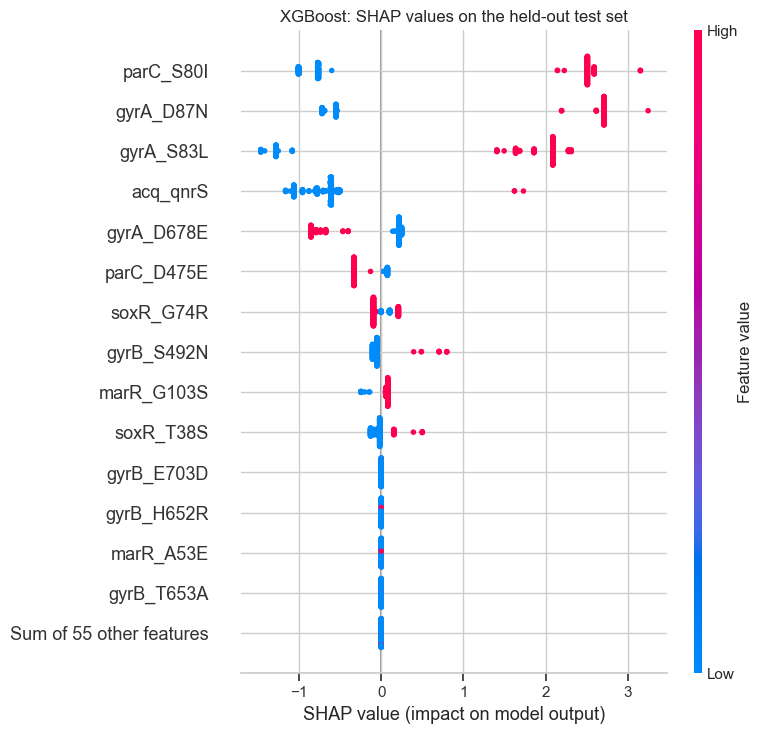

In [25]:
for name, explanation in explanations.items():
    plt.figure()
    shap.plots.beeswarm(explanation, max_display=15, show=False)
    plt.title(f"{name}: SHAP values on the held-out test set")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"shap_beeswarm_{name.lower().replace(' ', '_')}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 3.4 Do the important features match known resistance mechanisms? (RQ1)

In [26]:
KEY_MUTATIONS = ["gyrA_S83L", "gyrA_D87N", "gyrA_D87Y", "parC_S80I", "parC_E84V", "parC_E84G",
                 "parE_S458A", "parE_L416F", "acq_qnrS", "acq_qnrB", "acq_aac(6')-Ib-cr"]

ranks = pd.DataFrame({
    name: table.set_index("feature")["rank"].reindex(KEY_MUTATIONS)
    for name, table in importance_tables.items()
})
ranks["present in test isolates"] = [int(X_test[f].sum()) if f in X_test else 0 for f in KEY_MUTATIONS]
print("Rank of established resistance mechanisms among all features (1 = most important; "
      "blank = removed by the rare-feature filter or not observed)")
display(ranks)

top_categories = pd.DataFrame({
    name: table.head(10)["category"].map(CATEGORY_LABELS).value_counts()
    for name, table in importance_tables.items()
}).fillna(0).astype(int)
print("\nCategories of the 10 most important features per model")
display(top_categories)

Rank of established resistance mechanisms among all features (1 = most important; blank = removed by the rare-feature filter or not observed)


,Logistic Regression,Random Forest,XGBoost,present in test isolates
feature,,,,
gyrA_S83L,3.0,3.0,3.0,190
gyrA_D87N,2.0,2.0,2.0,156
gyrA_D87Y,42.0,24.0,49.0,3
parC_S80I,1.0,1.0,1.0,158
parC_E84V,15.0,22.0,40.0,109
...,...,...,...,...
parE_S458A,14.0,5.0,28.0,19
parE_L416F,12.0,12.0,26.0,11
acq_qnrS,7.0,4.0,4.0,3



Categories of the 10 most important features per model


,Logistic Regression,Random Forest,XGBoost
category,,,
Acquired resistance gene,1,1,1
Other substitution (possible lineage marker),6,4,6
Target-site QRDR mutation,3,5,3


## 3.5 How much do the models rely on lineage markers? (RQ2)
The share of total |SHAP| attributed to each category shows how much of each model's reasoning
comes from known mechanisms vs other substitutions. For the most important 'other' features, lineage
concentration is the share of isolates carrying the feature that belong to a single lineage cluster:
values near 100% indicate a lineage marker.

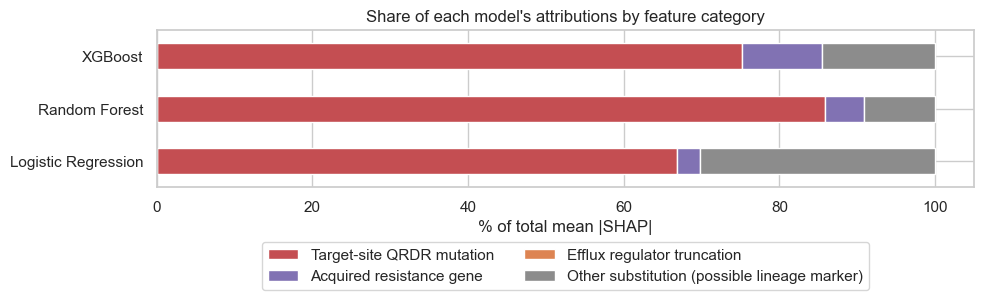

,Logistic Regression,Random Forest,XGBoost
category,,,
Target-site QRDR mutation,66.8,85.9,75.2
Acquired resistance gene,3.0,4.9,10.3
Efflux regulator truncation,0.0,0.0,0.0
Other substitution (possible lineage marker),30.2,9.2,14.6


In [27]:
shares = pd.DataFrame({
    name: table.groupby("category")["mean_abs_shap"].sum() / table["mean_abs_shap"].sum()
    for name, table in importance_tables.items()
}).reindex(list(CATEGORY_COLOURS)).fillna(0).rename(index=CATEGORY_LABELS)
shares.to_csv(RESULTS_DIR / "shap_share_by_category.csv")

ax = (100 * shares.T).plot(kind="barh", stacked=True, figsize=(10, 3.5),
                           color=list(CATEGORY_COLOURS.values()))
ax.set_xlabel("% of total mean |SHAP|")
ax.set_title("Share of each model's attributions by feature category")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_share_by_category.png", dpi=200, bbox_inches="tight")
plt.show()
display((100 * shares).round(1))

In [28]:
all_isolates = pd.concat([X_dev, X_test])
isolate_clades = clades.loc[all_isolates.index]

rows = []
for name, table in importance_tables.items():
    for _, row in table[table.category == "other"].head(10).iterrows():
        carriers = isolate_clades[all_isolates[row.feature] == 1]
        rows.append({
            "model": name, "feature": row.feature, "rank": row["rank"],
            "mean_abs_shap": row.mean_abs_shap, "isolates_with_feature": len(carriers),
            "lineages_with_feature": carriers.nunique(),
            "lineage_concentration_%": 100 * carriers.value_counts(normalize=True).iloc[0] if len(carriers) else np.nan,
        })
lineage_markers = pd.DataFrame(rows)
lineage_markers.to_csv(RESULTS_DIR / "shap_lineage_markers.csv", index=False)
display(lineage_markers.round(2))

,model,feature,rank,mean_abs_shap,isolates_with_feature,lineages_with_feature,lineage_concentration_%
0,Logistic Regression,gyrA_D678E,4,0.83,229,95,6.99
1,Logistic Regression,parC_D475E,5,0.53,275,87,37.45
2,Logistic Regression,gyrA_A828S,6,0.20,243,59,43.21
3,Logistic Regression,soxR_G74R,8,0.15,329,96,31.91
4,Logistic Regression,soxR_T38S,9,0.15,95,39,12.63
...,...,...,...,...,...,...,...
25,XGBoost,soxR_T38S,10,0.07,95,39,12.63
26,XGBoost,parC_S405L,11,0.00,6,2,83.33
27,XGBoost,parC_R406W,12,0.00,4,3,50.00
28,XGBoost,parE_D475E,13,0.00,7,3,71.43


## 3.6 Agreement between models
Spearman correlation of feature importance between models (features kept by both models).

In [29]:
names = list(importance_tables)
agreement = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        merged = importance_tables[a].merge(importance_tables[b], on="feature")
        agreement.loc[a, b] = merged["mean_abs_shap_x"].corr(merged["mean_abs_shap_y"], method="spearman")
display(agreement.round(2))

,Logistic Regression,Random Forest,XGBoost
Logistic Regression,1.00,0.73,0.53
Random Forest,0.73,1.00,0.50
XGBoost,0.53,0.50,1.00


## 3.7 Interaction between gyrA and parC mutations
High-level ciprofloxacin resistance usually needs a gyrA mutation plus a parC mutation. The dependence
plot shows whether the model's contribution for gyrA S83L changes with parC S80I.

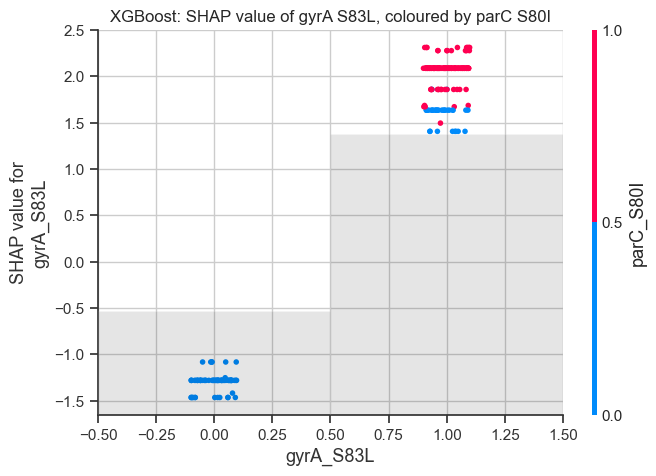

In [30]:
explanation = explanations["XGBoost"]
if {"gyrA_S83L", "parC_S80I"} <= set(explanation.feature_names):
    shap.plots.scatter(explanation[:, "gyrA_S83L"], color=explanation[:, "parC_S80I"], show=False)
    plt.title("XGBoost: SHAP value of gyrA S83L, coloured by parC S80I")
    plt.savefig(FIG_DIR / "shap_dependence_gyrA_parC.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("gyrA_S83L or parC_S80I was not kept by the XGBoost feature filter.")

## 3.8 Explaining individual predictions
Waterfall plots for one isolate of each outcome (XGBoost). They show how each feature moved the
prediction from the average (base value) to the final score for that isolate.

True positive (resistant, predicted resistant)
  isolate FDA-CDC-AR_0006, MIC 8.0 mg/L, predicted probability 0.98


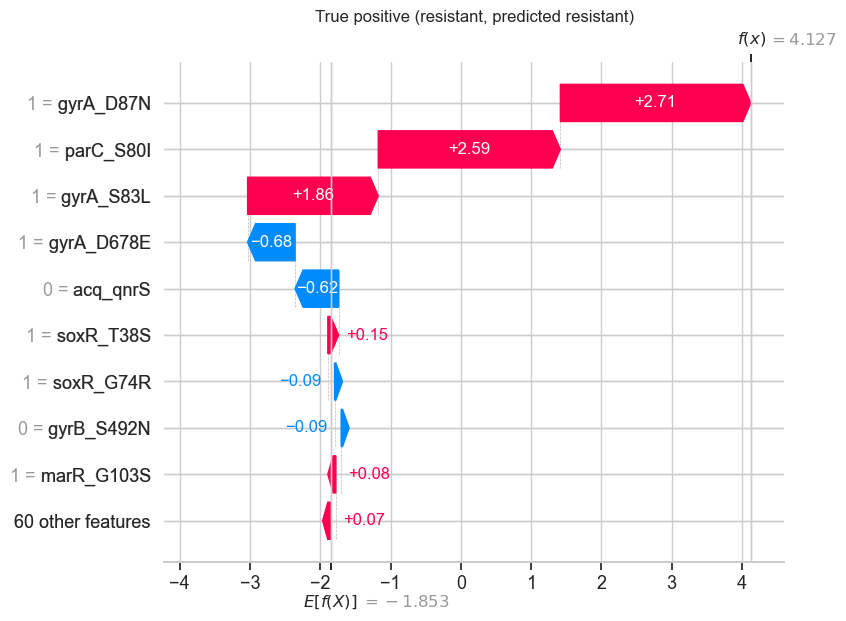

True negative (susceptible, predicted susceptible)
  isolate FDA-CDC-AR_0013, MIC 0.25 mg/L, predicted probability 0.08


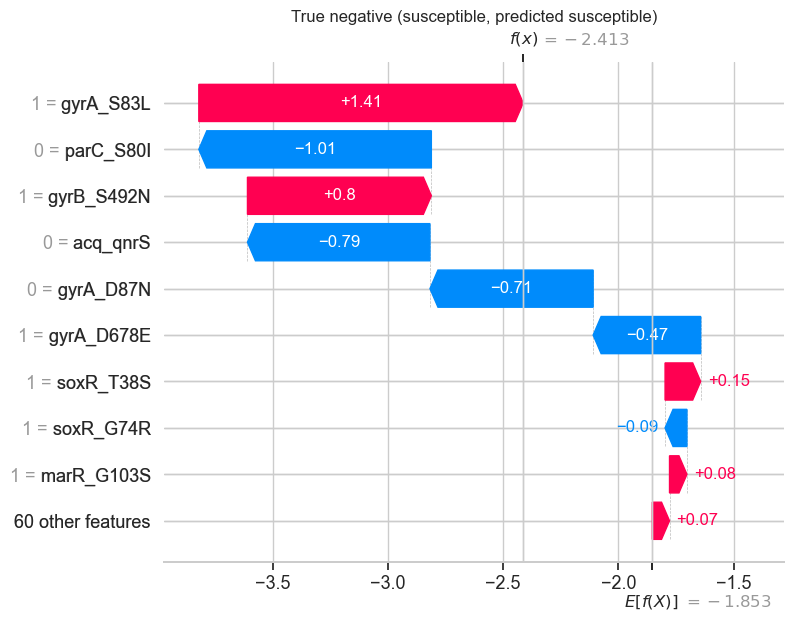

False negative (resistant, predicted susceptible)
  isolate SAMD00126469, MIC 1.0 mg/L, predicted probability 0.05


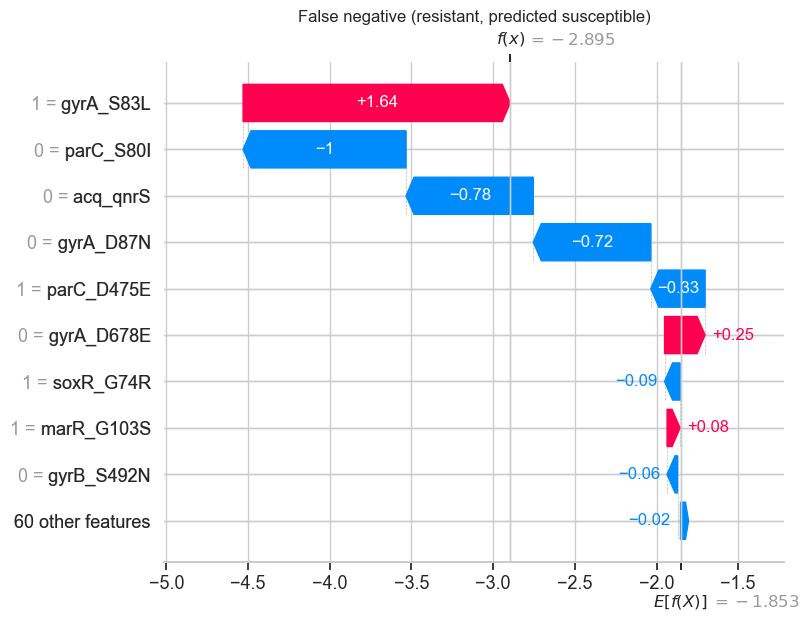

False positive (susceptible, predicted resistant): none in the test set



In [31]:
explanation = explanations["XGBoost"]
prob = models["XGBoost"].predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
outcomes = {
    "True positive (resistant, predicted resistant)": (y_test.to_numpy() == 1) & (pred == 1),
    "True negative (susceptible, predicted susceptible)": (y_test.to_numpy() == 0) & (pred == 0),
    "False negative (resistant, predicted susceptible)": (y_test.to_numpy() == 1) & (pred == 0),
    "False positive (susceptible, predicted resistant)": (y_test.to_numpy() == 0) & (pred == 1),
}
mic = data["measurement"]
for title, mask in outcomes.items():
    if not mask.any():
        print(f"{title}: none in the test set\n")
        continue
    i = int(np.flatnonzero(mask)[0])
    isolate = X_test.index[i]
    print(f"{title}\n  isolate {isolate}, MIC {mic[isolate]} mg/L, predicted probability {prob[i]:.2f}")
    shap.plots.waterfall(explanation[i], max_display=10, show=False)
    plt.title(title)
    plt.savefig(FIG_DIR / f"shap_waterfall_{title.split(' (')[0].lower().replace(' ', '_')}.png",
                dpi=200, bbox_inches="tight")
    plt.show()

## 3.9 Summary for the dissertation

In [32]:
for name, table in importance_tables.items():
    top5 = ", ".join(table.head(5)["feature"])
    known_share = 100 * (1 - shares.loc[CATEGORY_LABELS["other"], name])
    print(f"{name}\n  top 5 features: {top5}\n  share of attribution from known mechanisms: {known_share:.1f}%\n")

Logistic Regression
  top 5 features: parC_S80I, gyrA_D87N, gyrA_S83L, gyrA_D678E, parC_D475E
  share of attribution from known mechanisms: 69.8%

Random Forest
  top 5 features: parC_S80I, gyrA_D87N, gyrA_S83L, acq_qnrS, parE_S458A
  share of attribution from known mechanisms: 90.8%

XGBoost
  top 5 features: parC_S80I, gyrA_D87N, gyrA_S83L, acq_qnrS, gyrA_D678E
  share of attribution from known mechanisms: 85.4%

